# Cricketer Face Recognition Using CNN

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D
from keras.layers import Flatten, Dense, Dropout
from keras.utils import to_categorical



In [ ]:
128*128*3

49152

## Load CSV Dataset

In [2]:
df=pd.read_csv("/content/cricketer_dataset.csv")

In [3]:
df.shape

(1500, 49153)

(1500, 49153)

## Separate Features and Target

In [4]:

# Separate Features and Target
X = df.drop("Target", axis=1).values
Y = df["Target"]


In [5]:
X = np.array(X)

Y = np.array(Y)



(1500, 49152)

In [6]:
Y

array(['Virat Kohli', 'Virat Kohli', 'Virat Kohli', ..., 'MS Dhoni',
       'MS Dhoni', 'MS Dhoni'], dtype=object)

## Encode Target Labels

In [7]:
encoder = LabelEncoder()

Y = encoder.fit_transform(Y)

print(Y)


[4 4 4 ... 2 2 2]


## One Hot Encoding

In [8]:
Y = to_categorical(Y)

## Reshape Images for CNN

In [9]:
X = X.reshape(-1,128,128,3)

## Normalize Data

In [10]:
X = X / 255

## Train Test Split

In [11]:
xtrain, xtest, ytrain, ytest = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)


## Build CNN Model

In [12]:

from keras.layers import  BatchNormalization

model = Sequential()

# =========================
# BLOCK 1
# =========================

model.add(
    Conv2D(
        filters=32,
        kernel_size=(3,3),
        activation='relu',
        padding='same',
        input_shape=(128,128,3)
    )
)

model.add(BatchNormalization())

model.add(
    Conv2D(
        filters=32,
        kernel_size=(3,3),
        activation='relu',
        padding='same'
    )
)

model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Dropout(0.25))

# =========================
# BLOCK 2
# =========================

model.add(
    Conv2D(
        filters=64,
        kernel_size=(3,3),
        activation='relu',
        padding='same'
    )
)

model.add(BatchNormalization())

model.add(
    Conv2D(
        filters=64,
        kernel_size=(3,3),
        activation='relu',
        padding='same'
    )
)

model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Dropout(0.25))

# =========================
# BLOCK 3
# =========================

model.add(
    Conv2D(
        filters=128,
        kernel_size=(3,3),
        activation='relu',
        padding='same'
    )
)

model.add(BatchNormalization())

model.add(
    Conv2D(
        filters=128,
        kernel_size=(3,3),
        activation='relu',
        padding='same'
    )
)

model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Dropout(0.25))

# =========================
# FLATTEN
# =========================

model.add(Flatten())

# =========================
# DENSE LAYERS
# =========================

model.add(Dense(256, activation='relu'))

model.add(BatchNormalization())

model.add(Dropout(0.5))

model.add(Dense(128, activation='relu'))

model.add(Dropout(0.3))

# =========================
# OUTPUT LAYER
# =========================

model.add(
    Dense(
        units=Y.shape[1],
        activation='softmax'
    )
)



/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Compile Model

In [13]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

## Train Model

In [14]:
history = model.fit(
    xtrain,
    ytrain,
    validation_data=(xtest, ytest),
    epochs=20,
    batch_size=32
)

Epoch 1/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 36s 451ms/step - accuracy: 0.3058 - loss: 1.9021 - val_accuracy: 0.1867 - val_loss: 2.2956
Epoch 2/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.3925 - loss: 1.4755 - val_accuracy: 0.1833 - val_loss: 2.0642
Epoch 3/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.3808 - loss: 1.5535 - val_accuracy: 0.2500 - val_loss: 2.0395
Epoch 4/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.4083 - loss: 1.4632 - val_accuracy: 0.1900 - val_loss: 4.2563
Epoch 5/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.4383 - loss: 1.4487 - val_accuracy: 0.2633 - val_loss: 2.5487
Epoch 6/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.4583 - loss: 1.3677 - val_accuracy: 0.2500 - val_loss: 2.3590
Epoch 7/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 0.4842 - loss: 1.3103 - val_accuracy: 0.2900 - val_loss: 2.3511
Epoch 8/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy: 0.5550 - loss: 1.1534 - val_accuracy: 0.2700 -

## Evaluate Model

In [15]:
model.evaluate(xtest, ytest)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5567 - loss: 1.8402


[1.8401774168014526, 0.5566666722297668]

## Accuracy Graph

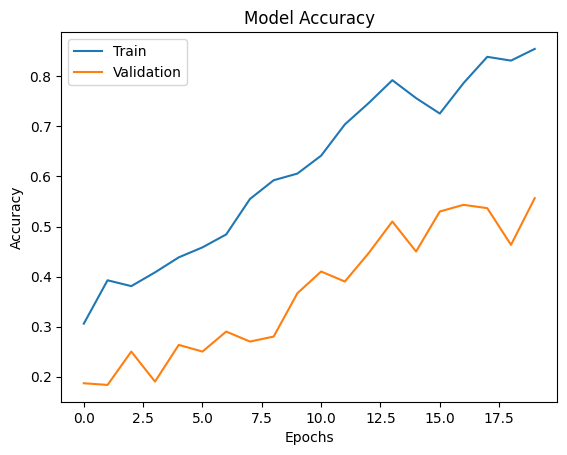

In [16]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend(["Train","Validation"])

plt.show()


## Prediction on New Image

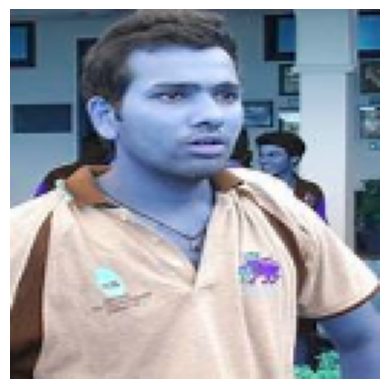

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Predicted Player: Jasprit Bumrah


In [20]:
import cv2
img = cv2.imread("rohittest.jpg")

img = cv2.resize(img, (128,128))

plt.imshow(img)
plt.axis('off')
plt.show()

img = img.reshape(1,128,128,3)

img = img / 255

pred = model.predict(img)

predicted_class = np.argmax(pred)

print(
    "Predicted Player:",
    encoder.inverse_transform([predicted_class])[0]
)


In [21]:
model.save("my_model.h5")